# 2. Data preprocessing

What happens to the data between Earth Engine and the model. The small demonstrations use made-up numbers to show each step and need no data.
The sections marked "needs the data" run only where the exported dataset is available.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "lulc").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
RES = ROOT / "results"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "axes.grid": False})

# Where the exported data and full runs live. Set LULC_BASE to your own folder. Not needed to read or re-run this notebook.
BASE = os.environ.get("LULC_BASE", "/home/jovyan/vault/lulc" if Path("/home/jovyan/vault/lulc").is_dir() else str(ROOT / "data"))
OUT, RUNS, RUNS_MY = f"{BASE}/raw", f"{BASE}/runs", f"{BASE}/runs_multiyear"
PROJECT = os.environ.get("EE_PROJECT", "")     # your own Earth Engine project; no ID is stored in the repo
V12 = "V12_window3_balanced_stats"             # the shipped model

RUN_EDA_ON_DATA = False     # True re-runs the slow steps below. They need Earth Engine and/or a GPU. Left False, nothing is downloaded or trained.
print("repo:", ROOT.name, "| data folder found:", Path(OUT).is_dir(), "|", "RUN_EDA_ON_DATA =", RUN_EDA_ON_DATA)

repo: sentinel1-lulc | data folder found: False | RUN_EDA_ON_DATA = False


## Preprocessing steps
| Step | What is done |
|---|---|
| Calibration and dB | Earth Engine's `S1_GRD`: thermal noise removal, radiometric calibration, geometric terrain correction, then dB |
| Terrain | Geometric correction only. No radiometric terrain flattening, stated as a limitation |
| Speckle | No spatial filter. The monthly temporal median reduces speckle |
| Monthly composite | Median in dB of the dominant orbit direction per month |
| Storage | dB stored as uint8 codes, with code 0 as no-data (`src/lulc/quant.py`) |
| Label matching | Dynamic World and Sentinel-1 come from one request on one grid, per month |
| Classes | Dynamic World's 9 classes are mapped to 6. Flooded vegetation and snow/ice are ignored |
| Input channels | A 3-month window of VV and VH, plus 5 yearly statistics |
| Normalisation | Mean and standard deviation per channel, from the training regions, saved in the model card |
| Patching | 256 x 256 px patches in training, drawn so that every region counts equally |
| Augmentation | The 8 flips and 90-degree rotations |

## Classes
The value 255 marks pixels that are ignored in the loss and in the metrics.

In [2]:
from lulc.classes import CLASS_NAMES, IGNORE_INDEX, remap_dynamic_world
dw_names = ["water", "trees", "grass", "flooded vegetation", "crops", "shrub and scrub", "built", "bare", "snow and ice"]
mapped = remap_dynamic_world(np.arange(9))
display(pd.DataFrame({"Dynamic World class": dw_names, "model class": [CLASS_NAMES[m] if m != IGNORE_INDEX else "ignored (255)" for m in mapped]}))

,Dynamic World class,model class
0,water,Water
1,trees,Tree cover
2,grass,Grass/shrub
3,flooded vegetation,ignored (255)
4,crops,Cropland
5,shrub and scrub,Grass/shrub
6,built,Built-up
7,bare,Bare
8,snow and ice,ignored (255)


## Class distribution
The classes are very unequal. The class weights and the equal region sampling exist because of this.

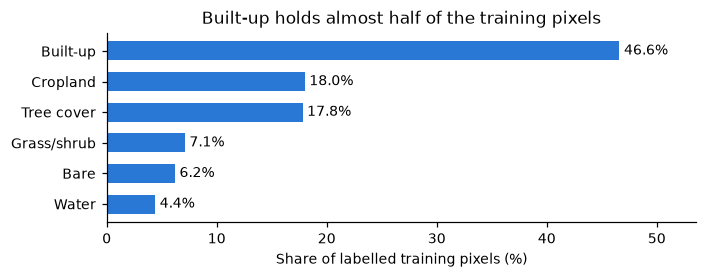

,class,share_pct
0,Built-up,46.6
1,Cropland,18.0
2,Tree cover,17.8
3,Grass/shrub,7.1
4,Bare,6.2
5,Water,4.4


In [3]:
cd = pd.read_csv(RES / "tables" / "class_distribution.csv").sort_values("share_pct")
fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(cd["class"], cd.share_pct, color="#2a78d6", height=0.62)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(xlabel="Share of labelled training pixels (%)", title="Built-up holds almost half of the training pixels")
ax.set_xlim(0, cd.share_pct.max() * 1.15)
plt.tight_layout(); plt.show()
display(cd.sort_values("share_pct", ascending=False).reset_index(drop=True))

## From dB to stored codes

In [4]:
from lulc.quant import quantize_db, dequantize_db
db = np.array([-30.0, -15.0, 0.0, np.nan], np.float32)
codes = quantize_db(db)
print("dB in:    ", db); print("codes:    ", codes); print("dB out:   ", dequantize_db(codes), " (code 0 comes back as no-data)")

dB in:     [-30. -15.   0.  nan]
codes:     [ 25 100 175   0]
dB out:    [-30. -15.   0.  nan]  (code 0 comes back as no-data)


## Input channels and normalisation of the shipped model
Read from its model card, the same file the prototype reads, so training and inference cannot drift apart.

In [5]:
card = json.loads((RES / "runs_multiyear" / V12 / "seed0" / "model_card.json").read_text())
print("window months:", card["window_months"], "| patch:", card["patch"], "| channels per month + yearly statistics:", card["channels"])
print("model input channels:", 2 * card["window_months"] + card["n_stat"], "(2 per month in the window, plus the yearly statistics)")
display(pd.DataFrame(card["norm"]).T.round(3))
print("Sampling and class settings:", {k: card["config"][k] for k in ("region_balance", "class_weight_power", "ce_weight", "dice_weight", "ema", "patience", "epochs")})

window months: 3 | patch: 256 | channels per month + yearly statistics: ['vv', 'vh', 'st0', 'st1', 'st2', 'st3', 'st4']
model input channels: 11 (2 per month in the window, plus the yearly statistics)


,mean,std
vv,-8.763,4.786
vh,-15.987,4.794
st0,-11.063,4.821
st1,-6.458,4.599
st2,1.443,0.772
st3,3.444,1.951
st4,0.024,0.128


Sampling and class settings: {'region_balance': 'equal', 'class_weight_power': 0.5, 'ce_weight': 1.0, 'dice_weight': 0.5, 'ema': 0.999, 'patience': 5, 'epochs': 12}


## Filling no-data months at inference
A month with no radar, or one that has not happened yet, would reach the model as a blank neighbour. At inference it takes the value of the next month towards the centre.
Training is unchanged, and the centre month is never changed. Made-up values, one row of pixels (code 0 = no-data):

In [6]:
from lulc.data import fill_window_gaps
stack = np.array([[[[0, 11, 12]]], [[[20, 21, 0]]], [[[30, 0, 32]]]], np.uint8)     # 3 months, 1 channel, 1 x 3 pixels
filled = fill_window_gaps(stack)
for name, x in (("before", stack), ("after", filled)):
    print(name, "| previous month", x[0, 0, 0], "| centre month", x[1, 0, 0], "| next month", x[2, 0, 0])

before | previous month [ 0 11 12] | centre month [20 21  0] | next month [30  0 32]
after | previous month [20 11 12] | centre month [20 21  0] | next month [30 21 32]


## Exploring the exported data (needs the data)
Backscatter by class, the seasonal signal and radar gaps. These cells read the export, so they run where the dataset is available.

In [7]:
import glob
from lulc.config import load_config
from lulc.data import load_store_ym
from lulc.quant import NODATA_CODE
YEAR, REGIONS = load_config("configs/regions.yaml")
HAVE = [r for r in REGIONS if glob.glob(f"{OUT}/{r.key}/{YEAR}-*.npz")]
train = [r for r in HAVE if r.split == "train"]
def month_sequence(year, month=1, n=12):
    i = year * 12 + month - 1
    return [((i + k) // 12, (i + k) % 12 + 1) for k in range(n)]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
RUN_EDA_ON_DATA = RUN_EDA_ON_DATA or bool(train)
print(len(HAVE), "of", len(REGIONS), "regions exported | exploring the data:", RUN_EDA_ON_DATA)

0 of 67 regions exported | exploring the data: False


In [8]:
if RUN_EDA_ON_DATA:

    # Backscatter per class, sampled from one month of each training region
    rng = np.random.default_rng(0); PER = 40000
    vv_by = [[] for _ in range(6)]; vh_by = [[] for _ in range(6)]
    for r in train:
        st = load_store_ym(OUT, r.key, month_sequence(YEAR), r.split)
        t = int(np.flatnonzero(st.present)[0])
        vv, vh, lab = dequantize_db(st.s1[t, 0]), dequantize_db(st.s1[t, 1]), st.label[t]
        idx = np.flatnonzero((st.s1[t, 0] != NODATA_CODE) & (lab != 255))
        if idx.size > PER:
            idx = rng.choice(idx, PER, replace=False)
        fv, fh, fl = vv.ravel()[idx], vh.ravel()[idx], lab.ravel()[idx]
        for k in range(6):
            vv_by[k].append(fv[fl == k]); vh_by[k].append(fh[fl == k])
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3), sharey=False)
    for ax, data, name in ((axes[0], vv_by, "VV (dB)"), (axes[1], vh_by, "VH (dB)")):
        ax.boxplot([np.concatenate(d) if d else np.array([]) for d in data], showfliers=False, widths=0.55, medianprops=dict(color="#2a78d6", linewidth=2))
        ax.set_xticks(range(1, 7), CLASS_NAMES, rotation=30, ha="right"); ax.set_title(name)
    plt.tight_layout(); plt.show()

In [9]:
if RUN_EDA_ON_DATA:

    # Seasonal signal: mean backscatter per month, averaged over the training regions
    mv = np.full((len(train), 12), np.nan); mh = mv.copy()
    for i, r in enumerate(train):
        st = load_store_ym(OUT, r.key, month_sequence(YEAR), r.split)
        for t in range(12):
            if st.present[t]:
                ok = st.s1[t, 0] != NODATA_CODE
                if ok.any():
                    mv[i, t] = dequantize_db(st.s1[t, 0])[ok].mean(); mh[i, t] = dequantize_db(st.s1[t, 1])[ok].mean()
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.6))
    for ax, data, name, colour in ((axes[0], mv, "VV", "#2a78d6"), (axes[1], mh, "VH", "#eb6834")):
        ax.plot(MONTHS, np.nanmean(data, 0), color=colour, lw=2, marker="o", ms=5)
        ax.set(title=f"Mean {name} by month", ylabel="dB")
    plt.tight_layout(); plt.show()

In [10]:
if RUN_EDA_ON_DATA:

    # Radar gaps: share of no-data pixels per region, worst 20
    rows = []
    for r in HAVE:
        st = load_store_ym(OUT, r.key, month_sequence(YEAR), r.split)
        rows.append((f"{r.key} ({r.split})", float((st.s1[st.present][:, 0] == NODATA_CODE).mean()) * 100))
    rows = sorted(rows, key=lambda x: x[1])[-20:]
    fig, ax = plt.subplots(figsize=(7, max(3, 0.24 * len(rows))))
    ax.barh([k for k, _ in rows], [v for _, v in rows], color="#2a78d6", height=0.62)
    ax.set(xlabel="No-data radar pixels (%)", title="Regions with the most radar gaps, " + str(YEAR))
    plt.tight_layout(); plt.show()
    print("regions above 5% no-data:", [(k, round(v, 1)) for k, v in rows if v > 5])

**Next:** `03_train_validate_test.ipynb`.